In [1]:
import numpy as np
import os
import seaborn as sns
import pandas as pd
from sklearn.mixture import GaussianMixture
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors

from omt.functions import sample_gmm_kdim, mmd_rbf, dynamic_points_transport #points_transport
from omt.solver import omt, ot_w2, ot_sinkh
from omt.visulization_tools import plot_gmm_ellipses
from omt.general_solver import omt, sample_mm, mmd_rbf
from omt.exp_functions import points_transport
from utils import generate_s_curve_data, generate_cube_edge_samples

%load_ext autoreload
%autoreload 2

In [2]:
saving_path = './figures/noise_to_cube/'
os.makedirs(saving_path, exist_ok=True)
# set the optimization parameters
eps = 0.1
max_iter = int(1e5)
stop_thr = 1e-6
fontsize = 22

# set the vidualization parameters
color_source = '#ff715b'
color_target = '#29335C' 
color_omt = '#eeab00'


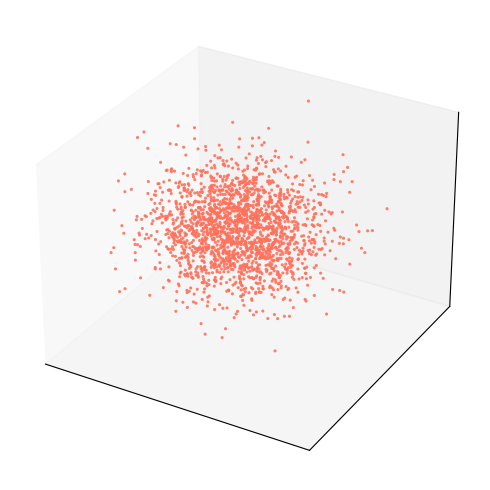

In [9]:
# Generate 2D Gaussian samples
n_samples = int(2000)
mean_0 = np.array([[.0, .0, 0.]]) # Mean vector [mean_x, mean_y]
# Covariance matrix: [[var_x, cov_xy], [cov_xy, var_y]]
# Must be symmetric and positive semi-definite
sigma_0 = np.array([[[1., 0., 0.], [0.0, 1, 0.], [0., 0., 1]]])
random_seed = 0

# Generate samples
# Returns shape (n_samples_2d, 2)
np.random.seed(random_seed)  # Set the random seed
samples_gauss_3d = np.random.multivariate_normal(mean=mean_0[0], cov=sigma_0[0], size=n_samples)

# plot the results
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(samples_gauss_3d[:, 0], samples_gauss_3d[:, 1], samples_gauss_3d[:, 2], s=5, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.9)
ax.axis('equal')
ax.grid(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])
# ax.axis('off')
ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
# ax.spines['top'].set_color('gray')
# ax.spines['right'].set_color('gray')
# ax.spines['left'].set_color('gray')
# ax.spines['bottom'].set_color('gray')
dx = .2
ax.set_xlim([np.min(samples_gauss_3d[:, 0]) - dx, np.max(samples_gauss_3d[:, 0]) + dx])
ax.set_ylim([np.min(samples_gauss_3d[:, 1]) - dx, np.max(samples_gauss_3d[:, 1]) + dx])
ax.set_zlim([np.min(samples_gauss_3d[:, 2]) - dx, np.max(samples_gauss_3d[:, 2]) + dx])
plt.tight_layout()
plt.savefig(saving_path + 'guass_3d.png', dpi=300)

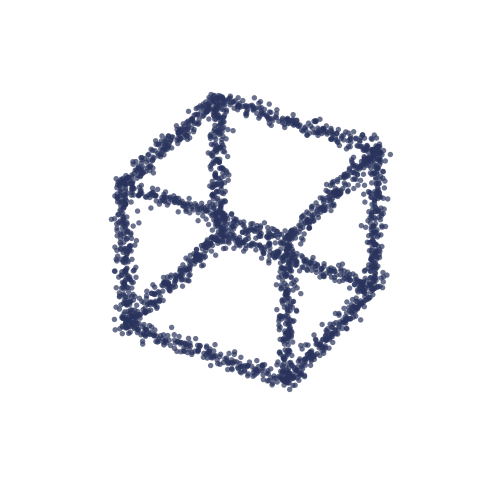

<Figure size 640x480 with 0 Axes>

In [4]:
cube_side_length = 2.0
# cube_center = np.array([0.0, 0.0, 0.0])
cube_center = np.array([0.5, 1.0, -0.5]) # Example with a non-origin center
points_on_each_edge = 200 # Try 1, 2, or more

# Generate edge samples
cube_samples = generate_cube_edge_samples(cube_side_length, points_on_each_edge, cube_center, noise_std=0.05)

# Plotting
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot the points
# Color the points based on the spiral parameter 't' to visualize the roll
scatter = ax.scatter(cube_samples[:, 0], 
                     cube_samples[:, 1],  
                     cube_samples[:, 2], 
                     s=15, 
                     c=color_target, 
                     facecolors=color_target, 
                     edgecolors='none', 
                     alpha=0.7)

ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax.axis('equal')
# ax.text(-5, -2, 5, 'Target', fontsize=fontsize)
ax.grid(False)
# ax.xaxis.line.set_color('gray')
# ax.yaxis.line.set_color('gray')
# ax.zaxis.line.set_color('gray')
# ax.set_xticks([])
# ax.set_yticks([])
# ax.set_zticks([])
ax.axis('off')
dx = 0.5
ax.set_xlim([np.min(cube_samples[:, 0]) - dx, np.max(cube_samples[:, 0]) + dx])
ax.set_ylim([np.min(cube_samples[:, 1]) - dx, np.max(cube_samples[:, 1]) + dx])
# ax.set_zlim([np.min(edge_samples[:, 2]) - dx, np.max(edge_samples[:, 2]) + dx])

plt.tight_layout()
ax.view_init(elev=35., azim=-60)

plt.show()
plt.tight_layout()
fig.savefig(saving_path + 'figure_2_cube_target.png', dpi=300, bbox_inches='tight')

In [5]:
K0 = 1
K1 = 50
omt_w, solver_dict = omt(
                        data_source=samples_gauss_3d,
                        data_target=cube_samples,
                        n_components=(K0, K1),
                        eps_gmm=eps,
                        eps_w=eps,
                        method='cvx',
                        fitting_mode_source='gauss',
                        fitting_mode_target='gauss',
                        cov_type='full',
                        max_iter=max_iter,
                        n_iter_em=1000,
                        stop_thr=stop_thr,
                        verbose=True,
                    )

/Users/yeganeh.marghi/miniconda3/envs/gmmot/lib/python3.10/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


Fitted a GMM with 1 components.
Model converged: True
Number of iterations: 2
--------------------------------------------------
Fitted a GMM with 50 components.
Model converged: True
Number of iterations: 21
--------------------------------------------------
Number of components in source: 1
Number of components in target: 50
Fitting mode: source=gauss, target=gauss
Time taken for fitting: 0.35918498039245605 seconds
Total transportation cost: 6.557226100243938
Discrepence in marginals' weights: 0.0 5.142270749806626e-11
Number of iterations: 150
Time taken for transportation optimzation: 0.014724016189575195 seconds
Number of total iterations: 173
Total time taken: 0.37390899658203125 seconds


In [10]:
mm_s_gauss = solver_dict['mm_s']
mm_t_gauss = solver_dict['mm_t']

transported_smp, _ = sample_mm(mm_t_gauss, n_samples=n_samples, random_state=2)

# compute Maximum Mean Discrepancy (MMD)
mmd = mmd_rbf(transported_smp, cube_samples, gamma=1.0)*100

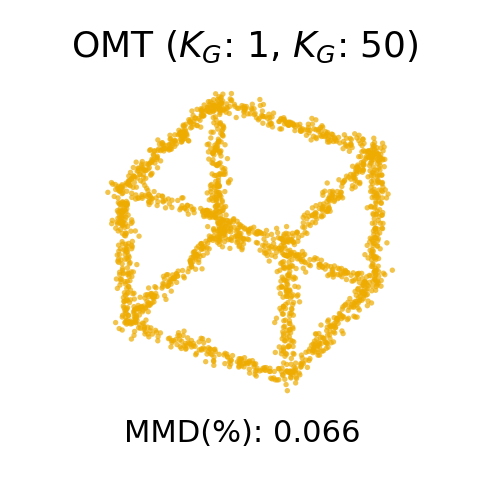

<Figure size 640x480 with 0 Axes>

In [23]:
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot the points
# Color the points based on the spiral parameter 't' to visualize the roll
scatter = ax.scatter(transported_smp[:, 0], 
                     transported_smp[:, 1],  
                     transported_smp[:, 2], 
                     s=15, 
                     c=color_omt, 
                     facecolors=color_target, 
                     edgecolors='none', 
                     alpha=0.7)

ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax.axis('equal')
ax.text2D(0.5, 0.9, rf'OMT ($K_G$: {K0}, $K_{{G}}$: {K1})', fontsize=fontsize+4, transform=ax.transAxes, ha='center')
ax.grid(False)
# ax.xaxis.line.set_color('gray')
# ax.yaxis.line.set_color('gray')
# ax.zaxis.line.set_color('gray')
# ax.set_xticks([])
# ax.set_yticks([])
# ax.set_zticks([])
ax.axis('off')

plt.tight_layout()
ax.view_init(elev=35., azim=-60)
dx = 0.5
ax.set_xlim([np.min(cube_samples[:, 0]) - dx, np.max(cube_samples[:, 0]) + dx])
ax.set_ylim([np.min(cube_samples[:, 1]) - dx, np.max(cube_samples[:, 1]) + dx])

ax.text2D(-.05, -.08, f'MMD(%): {mmd:.3f}', fontsize=fontsize)

plt.show()
plt.tight_layout()
fig.savefig(saving_path + 'figure_2_cube_omt_gauss.png', dpi=300, bbox_inches='tight')

In [30]:
K0 = 1
K1 = 20
omt_w, solver_dict = omt(
                        data_source=samples_gauss_3d,
                        data_target=cube_samples,
                        n_components=(K0, K1),
                        eps_gmm=eps,
                        eps_w=eps,
                        method='cvx',
                        fitting_mode_source='gauss',
                        fitting_mode_target='exp',
                        cov_type='diag',
                        max_iter=max_iter,
                        n_iter_em=1000,
                        stop_thr=stop_thr,
                        verbose=True,
                    )

Fitted a GMM with 1 components.
Model converged: True
Number of iterations: 2
--------------------------------------------------
Fitting Exp-only K=20, N=2400, D=3


/Users/yeganeh.marghi/github/GMM-OMT/omt/exp_functions.py:220: RuntimeWarning: overflow encountered in exp
  np.exp( d_rate * diff))


  EM done: 20A  BIC=2261.8

─── Result: 0 Gaussian + 20 Exp  BIC=2261.8 ───
  Exp 1: w=0.070  b=[ 1.494  2.014 -0.445]  c=[27.953 33.996  2.579]  d=[27.43  21.931  2.105]
  Exp 2: w=0.043  b=[-0.512  1.888  0.519]  c=[22.242 32.398 29.454]  d=[31.944  1.658 20.921]
  Exp 3: w=0.038  b=[ 1.51  -0.058 -1.551]  c=[26.592 12.143  2.779]  d=[ 19.395 103.976 145.847]
  Exp 4: w=0.074  b=[-0.504 -0.014 -0.324]  c=[20.081 21.489  2.752]  d=[29.386 32.841  1.814]
  Exp 5: w=0.058  b=[1.495 0.949 0.48 ]  c=[23.531  2.713 21.425]  d=[29.037  2.416 34.092]
  Exp 6: w=0.048  b=[-0.543  2.049 -1.519]  c=[ 5.195 43.194 13.523]  d=[63.452  6.579 28.287]
  Exp 7: w=0.034  b=[1.52  2.059 0.585]  c=[  42.483   52.828 1000.228]  d=[12.351  3.862  8.271]
  Exp 8: w=0.050  b=[ 1.507e+00 -1.000e-03 -9.540e-01]  c=[27.009 28.351  1.463]  d=[  23.902   27.897 1381.755]
  Exp 9: w=0.072  b=[ 1.142e+00 -1.000e-03 -1.497e+00]  c=[ 7.947 27.321 23.912]  d=[ 1.336 26.028 27.642]
  Exp 10: w=0.048  b=[-0.527 -0.085 

In [31]:
mm_s_gauss = solver_dict['mm_s']
mm_t_gauss = solver_dict['mm_t']

transported_smp, _ = sample_mm(mm_t_gauss, n_samples=n_samples, random_state=2)

# compute Maximum Mean Discrepancy (MMD)
mmd = mmd_rbf(transported_smp, cube_samples, gamma=1.0)*100

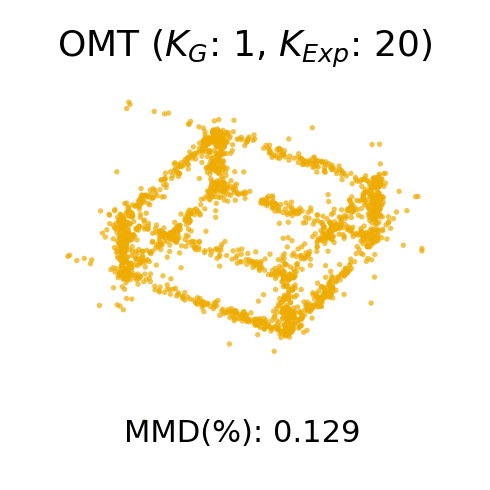

<Figure size 640x480 with 0 Axes>

In [32]:
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot the points
# Color the points based on the spiral parameter 't' to visualize the roll
scatter = ax.scatter(transported_smp[:, 0], 
                     transported_smp[:, 1],  
                     transported_smp[:, 2], 
                     s=15, 
                     c=color_omt, 
                     facecolors=color_target, 
                     edgecolors='none', 
                     alpha=0.7)

ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax.axis('equal')
ax.text2D(0.5, 0.9, rf'OMT ($K_G$: {K0}, $K_{{Exp}}$: {K1})', fontsize=fontsize+4, transform=ax.transAxes, ha='center')
ax.grid(False)
# ax.xaxis.line.set_color('gray')
# ax.yaxis.line.set_color('gray')
# ax.zaxis.line.set_color('gray')
# ax.set_xticks([])
# ax.set_yticks([])
# ax.set_zticks([])
ax.axis('off')

plt.tight_layout()
ax.view_init(elev=35., azim=-60)
dx = 0.5
ax.set_xlim([np.min(cube_samples[:, 0]) - dx, np.max(cube_samples[:, 0]) + dx])
ax.set_ylim([np.min(cube_samples[:, 1]) - dx, np.max(cube_samples[:, 1]) + dx])

ax.text2D(-.05, -.08, f'MMD(%): {mmd:.3f}', fontsize=fontsize)

plt.show()
plt.tight_layout()
fig.savefig(saving_path + 'figure_2_cube_omt_exp.png', dpi=300, bbox_inches='tight')